## 1. Imports
Import the libraries used throughout the notebook and log in to Kaggle so datasets can be downloaded.
A Kaggle login box appears under the cell: paste your API token and click **Login**. You can ignore it if the datasets are already downloaded.
Keras is set to run on PyTorch so training uses the GPU.

In [16]:
import importlib.util
import json
import os
import pickle
import platform
import random
import shutil
import subprocess
import sys

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.utils.class_weight import compute_class_weight

# Run Keras on PyTorch so training uses the GPU (TensorFlow has no GPU support on native Windows).
# This must be set before Keras is imported; restart the kernel after changing it.
os.environ["KERAS_BACKEND"] = "torch"
import keras
from keras.layers import (
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    MaxPooling2D,
)
from keras.models import Sequential
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,  # only used for data loading, not training
)

print(f"Keras backend: {keras.backend.backend()}") # just to make sure

# Show Kaggle's login box: paste your API token and click Login.
# The token is only kept while the kernel is running, and is not saved in the notebook.
# The notebook does not wait for the login, and Kaggle is only needed to download
# a dataset - so you can ignore the box if the datasets are already downloaded.
kagglehub.login()

Keras backend: torch


## 2. Set up the local environment
Install any missing packages and select the PyTorch device.
Training runs on this computer's NVIDIA GPU (CUDA) when PyTorch can see it, otherwise it falls back to the CPU.

In [17]:
# Print environment info
print(f"Python version: {platform.python_version()}")

# Install any missing packages using pip install
required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "torch": "torch",
    "torchvision": "torchvision",
    "tqdm": "tqdm",
    "Pillow": "PIL",
}

for package, module in required_packages.items():
    if importlib.util.find_spec(module) is None:
        print(f"Installing {package}...")
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", "-q", package
        ])

# Configure PyTorch
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"\nPyTorch: {torch.__version__} (CUDA {torch.version.cuda})")
print(f"Selected device: {device}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(
        f"GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )
print("Environment setup complete!")

Python version: 3.13.15

PyTorch: 2.11.0+cu128 (CUDA 12.8)
Selected device: cuda
GPU: NVIDIA GeForce RTX 5080
GPU memory: 15.89 GB
Environment setup complete!


## 3. Set the project directory
The project directory is the folder containing this notebook. All downloaded data is stored inside it, and trained models are saved in its `models` folder.

In [18]:
PROJECT_DIR = os.getcwd() # get current working directory
print(f"Project directory: {PROJECT_DIR}")

# Folder where trained models are saved as .pkl files
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)
print(f"Models directory: {MODELS_DIR}")

Project directory: c:\CNN AI Vision
Models directory: c:\CNN AI Vision\models


## 4. Look at the folders in the project directory
List what is already in the project directory and make it the working directory.

In [19]:
# List files and folders
for item in os.listdir(PROJECT_DIR):
    ITEM_PATH = os.path.join(PROJECT_DIR, item)
    if os.path.isdir(ITEM_PATH):
        print(f"📁 Folder: {item}")
    else:
        print(f"📄 File: {item}")

# go back to the project directory
print()
os.chdir(PROJECT_DIR)
print(f"Current working directory: {os.getcwd()}")

📄 File: .gitignore
📁 Folder: .streamlit
📁 Folder: .venv
📁 Folder: .venv-py315
📁 Folder: .vscode
📄 File: api.py
📁 Folder: app_pages
📁 Folder: data
📁 Folder: logs
📄 File: main.py
📁 Folder: models
📄 File: project03_cnn.pdf
📄 File: README.md
📄 File: reference work.ipynb
📄 File: requirements.txt
📄 File: streamlit_app.py
📁 Folder: vision
📁 Folder: __pycache__

Current working directory: c:\CNN AI Vision


## 5. Obtain the Training Data
Pick the type of model to train from the menu (press Escape or leave it empty to cancel):
1. Facial Expression Recognition
2. Face Mask Detection
3. Fruit and Vegetable Recognition

If the dataset is already in `data/<dataset name>` inside the project directory, the download is skipped. Otherwise it is downloaded from Kaggle into KaggleHub's local cache, then copied there.

Facial Expression Recognition: https://www.kaggle.com/datasets/subhaditya/fer2013plus (FER2013 images with Microsoft's corrected FER+ labels)  
Face Mask Detection: https://www.kaggle.com/datasets/shiekhburhan/face-mask-dataset  
Fruit and Vegetable Recognition: https://www.kaggle.com/datasets/moltean/fruits  


In [20]:
while True:
    menu_decision = input(
    "Select a training dataset:\n"
    "1. Facial Expression Recognition\n"
    "2. Face Mask Detection\n"
    "3. Fruit and Vegetable Recognition\n"
    "Enter the number of your choice (Escape or empty to cancel): "
)

    if menu_decision == "1":
        menu_decision = "Facial Expression Recognition"
        break
    elif menu_decision == "2":  
        menu_decision = "Face Mask Detection"
        break
    elif menu_decision == "3":
        menu_decision = "Fruit and Vegetable Recognition"
        break
    elif menu_decision.strip() == "":
        # Escape in the input box sends an empty answer, so treat it as cancel
        raise KeyboardInterrupt("Dataset selection cancelled.")
    else:
        print("Invalid choice. Please select a valid option.")

training_data = {
    "Facial Expression Recognition": {
        "dataset": "fer2013plus",
        "url": "https://www.kaggle.com/datasets/subhaditya/fer2013plus"
    },
    "Face Mask Detection": {
        "dataset": "face-mask-detection",
        "url": "https://www.kaggle.com/datasets/shiekhburhan/face-mask-dataset"
    },
    "Fruit and Vegetable Recognition": {
        "dataset": "fruits",
        "url": "https://www.kaggle.com/datasets/moltean/fruits"
    }
}

# Kaggle dataset URL for the selected option
dataset_url = training_data[menu_decision]["url"]

# The dataset ID is the part of the URL after "kaggle.com/datasets/", e.g. "moltean/fruits"
dataset_id = dataset_url.split("kaggle.com/datasets/")[1]

# Folder holding all datasets, and the folder for the selected dataset
DATA_DIR = os.path.join(PROJECT_DIR, "data")

DATASET_DIR = os.path.join(
    DATA_DIR,
    training_data[menu_decision]["dataset"]
)

# Skip the download if the dataset is already in the project's data folder
if os.path.isdir(DATASET_DIR) and os.listdir(DATASET_DIR):
    KAGGLE_CACHE_DIR = None
    print("Dataset already exists, skipping download.")
else:
    os.makedirs(DATASET_DIR, exist_ok=True)

    # Download dataset using KaggleHub's default cache
    KAGGLE_CACHE_DIR = kagglehub.dataset_download(dataset_id)

    # Copy dataset from the KaggleHub cache into the project's data folder
    shutil.copytree(
        KAGGLE_CACHE_DIR,
        DATASET_DIR,
        dirs_exist_ok=True
    )

    print("Dataset downloaded successfully!")

print(f"Dataset: {dataset_id}")
print(f"Saved to: {DATASET_DIR}")

# Display the dataset's folders as a tree.
# os.walk goes through DATASET_DIR and every folder inside it, one folder at a time (ROOT).
for ROOT, dirs, files in os.walk(DATASET_DIR):
    # How deep this folder is: the number of folder separators (os.sep) after DATASET_DIR
    level = ROOT.replace(DATASET_DIR, "").count(os.sep)
    indent = "    " * level  # 4 spaces for every level

    print(f"{indent}📁 {os.path.basename(ROOT)}/")

Dataset already exists, skipping download.
Dataset: subhaditya/fer2013plus
Saved to: c:\CNN AI Vision\data\fer2013plus
📁 fer2013plus/
    📁 fer2013plus/
        📁 fer2013/
            📁 test/
                📁 anger/
                📁 contempt/
                📁 disgust/
                📁 fear/
                📁 happiness/
                📁 neutral/
                📁 sadness/
                📁 surprise/
            📁 train/
                📁 anger/
                📁 contempt/
                📁 disgust/
                📁 fear/
                📁 happiness/
                📁 neutral/
                📁 sadness/
                📁 surprise/


Verify that the dataset exists in the project's data folder (and in the KaggleHub cache, if it was just downloaded).

In [21]:
for PATH in [KAGGLE_CACHE_DIR, DATASET_DIR]:
    # KAGGLE_CACHE_DIR is None if the download was skipped
    if PATH is None:
        continue

    print(f"\nChecking: {PATH}")
    print("Exists:", os.path.exists(PATH))
    print("Real path:", os.path.realpath(PATH))

    if os.path.isdir(PATH):
        print("Contents:", os.listdir(PATH)[:10])


Checking: c:\CNN AI Vision\data\fer2013plus
Exists: True
Real path: C:\CNN AI Vision\data\fer2013plus
Contents: ['fer2013plus', 'ferplus_port.py']


## 6. Settings and functions
The cells in this section only set up for training the chosen model

### 6.1 Settings
All the numbers that control training and the model, and the folders each dataset uses. Settings used by only one dataset are marked with its section in 7.

In [22]:
# Training parameters
target_accuracy = 0.925  # stop training once BOTH training and test accuracy reach 92.5%
max_epochs = 100         # if the target is never reached, stop after 100 epochs and keep the best epoch
batch_size = 64          # how many images the model looks at in one step

# Model parameters
conv_depth = 8           # number of convolution layers
start_filters = 64       # filters in the first two convolution layers (doubles every two layers)
max_filters = 512        # the number of filters never goes above this
conv_dropout = 0.25      # share of connections switched off after each pooling layer
dense_units = 256        # number of neurons in the fully connected layer
dense_dropout = 0.5      # share of connections switched off after the fully connected layer

# Image sizes
fer_image_size = (48, 48)  # 7.1 only - FER+ images are 48x48 grayscale
image_size = (64, 64)      # 7.2 and 7.3 - color images

# FER (Facial Expression Recognition) only
FER_DIR = os.path.join(DATASET_DIR, "fer2013plus", "fer2013")

# FMD (Face Mask Detection) only
# This dataset has no test folder, so 20% of the images are copied into one
test_share = 0.2
MASK_SPLIT_DIR = os.path.join(DATASET_DIR, "FMD_SPLIT")  # where the train/test copy is saved
mask_classes = ["with_mask", "without_mask"]  # the incorrect_mask folder is left out

# FVR (Fruit and Vegetable Recognition) only
FRUITS_DIR = os.path.join(DATASET_DIR, "fruits-360_100x100", "fruits-360")
fruit_names = ["Apple", "Avocado", "Banana", "Eggplant", "Tomato"]  # all varieties of a fruit become one class
dropped_fruit_varieties = [
    "Apple 23",  # photos of eaten apple cores - not what one would really consider to be an "apple"
]
FRUITS_SUBSET_DIR = os.path.join(DATASET_DIR, "fruits-subset")  # where the merged copy is saved

# Save the model in the `models` directory
# The trained model, e.g. models/Face Mask Detection.pkl
MODEL_PATH = os.path.join(MODELS_DIR, f"{menu_decision}.pkl")
# The class names, image size and color mode the Streamlit app needs, e.g. models/Face Mask Detection.json
CLASSES_PATH = os.path.join(MODELS_DIR, f"{menu_decision}.json")

### 6.2 Loading the images
Images are loaded from folders, where every sub-folder is one class (for example `with_mask` and `without_mask`).
Training images get small random changes (augmentation) so the model sees more variety. Test images are only normalized.

In [23]:
# Training images: normalize, plus small random changes
train_datagen = ImageDataGenerator(
    rescale=1./255,         # pixel values from 0-255 to 0-1
    rotation_range=10,      # rotate a little
    width_shift_range=0.1,  # move a little left or right
    height_shift_range=0.1, # move a little up or down
    zoom_range=0.1,         # zoom a little in or out
    horizontal_flip=True    # a mirrored image still shows the same class
)

# Test images: only normalize, no random changes
test_datagen = ImageDataGenerator(rescale=1./255)


def load_images(datagen, IMAGES_DIR, size, color_mode='rgb', classes=None, shuffle=True):
    # Load the images in IMAGES_DIR in batches. Every sub-folder is one class.
    # classes: which sub-folders to use (None means all of them)
    # shuffle: False keeps the images in a fixed order (the evaluation in 6.6 needs this)
    images = datagen.flow_from_directory(
        IMAGES_DIR,
        target_size=size,
        color_mode=color_mode,
        classes=classes,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=shuffle
    )
    return images

### 6.3 Preparing the datasets
Two datasets need a one-time copy of their images before training. Both functions skip the copy if it already exists.
- **Face Mask Detection** has no test folder, so its images are split into a train and a test folder.
- **Fruits 360** has a folder for every variety (`Apple Golden 1`, `Apple Red 2`, ...), so the varieties of each chosen fruit are merged into one folder per fruit.

Both copy into a temporary `_partial` folder first and rename it at the end. If a copy is interrupted, it starts over next time instead of using a half-finished folder.

In [24]:
def make_train_test_split(SOURCE_DIR, SPLIT_DIR, test_share):
    # Copy the images in SOURCE_DIR (one folder per class) into SPLIT_DIR/train and SPLIT_DIR/test.
    # test_share of every sub-folder goes to test, so each kind of photo is in both train and test.
    # The copies are made smaller (largest side 128 pixels) so training loads them faster.

    if os.path.isdir(SPLIT_DIR):
        print(f"Train/test split already exists: {SPLIT_DIR}")
        return

    # Start again if an earlier copy was interrupted
    PARTIAL_DIR = SPLIT_DIR + "_partial"
    if os.path.isdir(PARTIAL_DIR):
        shutil.rmtree(PARTIAL_DIR)

    random.seed(42)  # same split every time

    for class_name in sorted(os.listdir(SOURCE_DIR)):
        CLASS_DIR = os.path.join(SOURCE_DIR, class_name)

        # os.walk() goes through CLASS_DIR and every folder inside it
        for ROOT, dirs, files in os.walk(CLASS_DIR):
            # Keep only the image files, sort them, then shuffle them
            images = []
            for file_name in sorted(files):
                if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
                    images.append(file_name)
            random.shuffle(images)

            # The first test_count images go to test, the rest go to train
            test_count = round(len(images) * test_share)

            # The sub-folder's name is added to every file name, so files from different sub-folders can't clash
            sub_folder = os.path.relpath(ROOT, CLASS_DIR).replace(os.sep, "_")

            for k in range(len(images)):
                file_name = images[k]
                if k < test_count:
                    split = "test"
                else:
                    split = "train"

                OUT_DIR = os.path.join(PARTIAL_DIR, split, class_name)
                os.makedirs(OUT_DIR, exist_ok=True)

                name_without_extension = os.path.splitext(file_name)[0]
                OUT_PATH = os.path.join(OUT_DIR, f"{sub_folder}_{name_without_extension}.jpg")

                # Open the image, make it smaller (keeping its shape) and save it as a .jpg
                img = Image.open(os.path.join(ROOT, file_name)).convert("RGB")
                img.thumbnail((128, 128))
                img.save(OUT_PATH, quality=95)

    # Everything was copied, so give the folder its real name
    os.rename(PARTIAL_DIR, SPLIT_DIR)

    # Count the images in train and in test
    for split in ["train", "test"]:
        count = 0
        for ROOT, dirs, files in os.walk(os.path.join(SPLIT_DIR, split)):
            count = count + len(files)
        print(f"{split}: {count} images")
    print(f"Train/test split saved to: {SPLIT_DIR}")


def make_fruit_subset(SOURCE_DIR, SUBSET_DIR, fruit_names, dropped_varieties):
    # Copy every variety of each fruit in fruit_names into one folder per fruit.
    # For example "Apple Golden 1" and "Apple Red 2" both go into SUBSET_DIR/Training/Apple.
    # The varieties in dropped_varieties are left out.

    if os.path.isdir(SUBSET_DIR):
        print(f"Fruit subset already exists: {SUBSET_DIR}")
        return

    # Start again if an earlier copy was interrupted
    PARTIAL_DIR = SUBSET_DIR + "_partial"
    if os.path.isdir(PARTIAL_DIR):
        shutil.rmtree(PARTIAL_DIR)

    for split in ["Training", "Test"]:
        for folder in sorted(os.listdir(os.path.join(SOURCE_DIR, split))):
            # The first word of the folder name is the fruit: "Apple Golden 1" -> "Apple"
            # (so "Pineapple 1" does not count as an apple)
            fruit = folder.split()[0]
            if fruit not in fruit_names:
                continue  # not one of our fruits, skip this folder
            if folder in dropped_varieties:
                continue  # one of the dropped varieties, skip this folder

            OUT_DIR = os.path.join(PARTIAL_DIR, split, fruit)
            os.makedirs(OUT_DIR, exist_ok=True)

            for file_name in os.listdir(os.path.join(SOURCE_DIR, split, folder)):
                # The variety's name is added to every file name, so files from different varieties can't clash
                FROM_PATH = os.path.join(SOURCE_DIR, split, folder, file_name)
                TO_PATH = os.path.join(OUT_DIR, f"{folder}_{file_name}")
                shutil.copy(FROM_PATH, TO_PATH)

    # Everything was copied, so give the folder its real name
    os.rename(PARTIAL_DIR, SUBSET_DIR)

    # Count the images of every fruit
    for split in ["Training", "Test"]:
        for fruit in fruit_names:
            count = len(os.listdir(os.path.join(SUBSET_DIR, split, fruit)))
            print(f"{split} {fruit}: {count} images")
    print(f"Fruit subset saved to: {SUBSET_DIR}")

### 6.4 Building the CNN
The model has `conv_depth` convolution layers, added in a loop, followed by the fully connected layers. The last layer has one output per class.

In [25]:
def build_cnn(input_shape, num_classes):
    # input_shape: (height, width, channels) - 1 channel for grayscale, 3 for color
    cnn = Sequential()

    # ===== Convolution layers =====
    current_size = input_shape[0]  # the image size at this point in the model
    for i in range(conv_depth):
        # start_filters for layers 0-1, double for layers 2-3, double again for 4-5, ...
        filters = start_filters * 2 ** (i // 2)
        filters = min(filters, max_filters) # ruff caught me on an if statement

        if i == 0:
            # The first layer must be told the shape of the input images
            cnn.add(Conv2D(filters=filters, kernel_size=3, padding='same', activation='relu', input_shape=input_shape))
        else:
            cnn.add(Conv2D(filters=filters, kernel_size=3, padding='same', activation='relu'))

        # Rescale the layer's output so a deep model keeps learning (without this it can get stuck)
        cnn.add(BatchNormalization())

        # After every second convolution layer (i = 1, 3, 5, ...), halve the image size.
        # Stop halving once the image is 3x3 (e.g. 48 -> 24 -> 12 -> 6 -> 3)
        if i % 2 == 1 and current_size > 3:
            cnn.add(MaxPooling2D(pool_size=2, strides=2))
            current_size = current_size // 2

            # Randomly switch off some connections during training, so the model can't just memorize
            cnn.add(Dropout(conv_dropout))

    # flatten the output into a vector
    cnn.add(Flatten())

    # connected layers
    cnn.add(Dense(units=dense_units, activation='relu'))
    cnn.add(Dropout(dense_dropout))
    cnn.add(Dense(units=num_classes, activation='softmax'))  # one output per class

    cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return cnn

### 6.5 Training and saving
The model is trained one epoch at a time:
- Training stops as soon as **both** the training and the test accuracy reach `target_accuracy`.
- If that never happens in `max_epochs`, the model goes back to the epoch with the best **training accuracy + 2 × test accuracy** (test accuracy counts double because it is the more important metric).

After training, the model is saved to a `.pkl` (pickle lol) file, and its class names to a `.json` file for the Streamlit app.

In [26]:
def ask_to_retrain():
    # Returns True if a new model should be trained:
    # there is no saved model yet, or the user answers "y" to train it again
    if not os.path.exists(MODEL_PATH):
        return True

    answer = input(
        f"A trained model already exists: {MODEL_PATH}\n"
        "Train again and overwrite it? (y/N): "
    )
    return answer.strip().lower() in ("y", "yes") # ruff is good at catching me on if statements


def train_and_save(cnn, training_set, test_set, balance_classes=False):
    # Train the model, then save it to MODEL_PATH and its class names to CLASSES_PATH.
    # balance_classes=True gives classes with fewer images more weight,
    # so the model can't just keep guessing the class with the most images.

    # class weights
    class_weight = None
    if balance_classes:
        class_ids = np.unique(training_set.classes)  # 0, 1, 2, ... one number per class
        weights = compute_class_weight('balanced', classes=class_ids, y=training_set.classes)
        class_weight = {}
        for k in range(len(class_ids)):
            class_weight[class_ids[k]] = weights[k]

    # training (slow)
    # The results of every epoch
    history = {"accuracy": [], "val_accuracy": [], "loss": [], "val_loss": []}

    best_score = -1
    best_epoch = 0
    best_weights = None
    reached_target = False

    for epoch in range(1, max_epochs + 1):
        print(f"Epoch {epoch}/{max_epochs}")
        result = cnn.fit(x=training_set, validation_data=test_set, epochs=1, class_weight=class_weight)

        # Add this epoch's results to the history
        for key in history:
            history[key].append(result.history[key][0])

        train_accuracy = result.history["accuracy"][0]
        test_accuracy = result.history["val_accuracy"][0]  # "val" = the test images

        # Remember the weights of the best epoch so far (test accuracy counts double)
        score = train_accuracy + 2 * test_accuracy
        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_weights = cnn.get_weights()

        # Stop when both accuracies reach the target
        if train_accuracy >= target_accuracy and test_accuracy >= target_accuracy:
            reached_target = True
            break

    if reached_target:
        kept_epoch = epoch
        print(f"Both accuracies reached {target_accuracy:.1%} after {epoch} epochs")
    else:
        # Go back to the best epoch
        cnn.set_weights(best_weights)
        kept_epoch = best_epoch
        print(f"Target not reached in {max_epochs} epochs, keeping epoch {best_epoch} (best training + 2 x test accuracy)")

    kept_train_accuracy = history["accuracy"][kept_epoch - 1]  # lists start at 0, epochs start at 1
    kept_test_accuracy = history["val_accuracy"][kept_epoch - 1]
    print(f"Kept model: training accuracy {kept_train_accuracy:.2%}, test accuracy {kept_test_accuracy:.2%}")

    # Save the model, so it can be used again without training
    with open(MODEL_PATH, "wb") as f:
        pickle.dump(cnn, f)
    print(f"Model saved to: {MODEL_PATH}")

    # Save what the Streamlit app needs to prepare an image and name the prediction
    # class_indices looks like {"Apple": 0, "Avocado": 1, ...}, so its keys are the class names in the model's output order
    info = {
        "classes": list(training_set.class_indices.keys()),
        "image_size": list(training_set.target_size),
        "color_mode": training_set.color_mode,
    }
    with open(CLASSES_PATH, "w") as f:
        json.dump(info, f, indent=4)
    print(f"Class names saved to: {CLASSES_PATH}")

    return history


def load_saved_model():
    # Load the model that was trained and saved before
    with open(MODEL_PATH, "rb") as f:
        cnn = pickle.load(f)
    print(f"Loaded existing model: {MODEL_PATH}")
    return cnn

### 6.6 Evaluating the model
- **Training curves** — accuracy and loss for every epoch, on the training and the test images (only when the model was just trained).
- **Classification report** — precision, recall and F1-score for every class.
- **Confusion matrix** — rows are the real class, columns the predicted class. The diagonal holds the correct predictions.
- **Random test image** — shows one test image with the model's prediction.

In [27]:
def evaluate_model(cnn, history, IMAGES_DIR, size, color_mode='rgb', classes=None):
    # Training Curves, Classification Report and Confusion Matrix
    if history is not None:
        epochs = range(1, len(history["accuracy"]) + 1)  # 1, 2, 3, ...
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)  # left plot
        plt.plot(epochs, history["accuracy"], label="training")
        plt.plot(epochs, history["val_accuracy"], label="test")
        plt.title("Accuracy")
        plt.xlabel("Epoch")
        plt.legend()

        plt.subplot(1, 2, 2)  # right plot
        plt.plot(epochs, history["loss"], label="training")
        plt.plot(epochs, history["val_loss"], label="test")
        plt.title("Loss")
        plt.xlabel("Epoch")
        plt.legend()

        plt.show()

    # Load the test images again, this time NOT shuffled,
    # so the predictions come out in the same order as the real classes
    eval_set = load_images(test_datagen, IMAGES_DIR, size, color_mode, classes=classes, shuffle=False)
    class_names = list(eval_set.class_indices.keys())

    # The model gives a probability for every class; the predicted class is the one with the highest probability
    probabilities = cnn.predict(eval_set)
    predicted = np.argmax(probabilities, axis=1)
    actual = eval_set.classes

    print(classification_report(actual, predicted, target_names=class_names, digits=3, zero_division=0))

    matrix = confusion_matrix(actual, predicted)
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(cmap='Blues', xticks_rotation=45)
    plt.title('Confusion matrix')
    plt.show()


def predict_random_test_image(cnn, test_set, size, color_mode='rgb'):
    # Show a random test image, then print what the model thinks it is and what it really is
    class_names = list(test_set.class_indices.keys())

    # Pick a random test image
    k = np.random.randint(len(test_set.filepaths))
    IMG_PATH = test_set.filepaths[k]

    # Show it (grayscale images need cmap='gray', otherwise they are shown in color)
    if color_mode == 'grayscale':
        plt.imshow(image.load_img(IMG_PATH, color_mode=color_mode), cmap='gray')
    else:
        plt.imshow(image.load_img(IMG_PATH, color_mode=color_mode))
    plt.axis('off')
    plt.show()

    # Prepare the image the same way as in training
    test_image = image.load_img(IMG_PATH, target_size=size, color_mode=color_mode)  # 1. resize it
    test_image = image.img_to_array(test_image) / 255.0  # 2. turn it into numbers from 0 to 1
    test_image = np.expand_dims(test_image, axis=0)      # 3. the model expects a batch of images, so make a batch of 1

    # One probability for every class
    result = cnn.predict(test_image)[0]

    # Print the most likely classes (5 at most)
    order = np.argsort(result)  # class numbers, from least to most likely
    order = order[::-1]         # reverse it, so the most likely class comes first
    for index in order[:5]:
        print(f"{class_names[index]}: {result[index]:.3f}")

    prediction = class_names[np.argmax(result)]
    actual = class_names[test_set.classes[k]]
    print(f"Prediction: {prediction} (actual: {actual})")

## 7. Training using the chosen dataset
Only the cell for the dataset chosen in section 5 runs; the other two print "Skipped". The chosen cell:
1. loads the training and test images
2. trains a new model (or loads the saved one, if you choose not to train again)
3. evaluates the model on the test images
4. predicts a random test image

### 7.1 Facial Expression Recognition (FER+)

Found 28386 images belonging to 8 classes.
Found 7099 images belonging to 8 classes.


c:\CNN AI Vision\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 26s 58ms/step - accuracy: 0.3651 - loss: 1.8451 - val_accuracy: 0.4130 - val_loss: 1.5381
Epoch 2/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.5217 - loss: 1.3735 - val_accuracy: 0.5852 - val_loss: 1.2092
Epoch 3/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - accuracy: 0.6205 - loss: 1.1494 - val_accuracy: 0.6287 - val_loss: 1.0963
Epoch 4/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.6543 - loss: 1.0352 - val_accuracy: 0.6977 - val_loss: 0.8810
Epoch 5/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.6810 - loss: 0.9585 - val_accuracy: 0.6718 - val_loss: 0.9753
Epoch 6/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.6901 - loss: 0.9208 - val_accuracy: 0.7263 - val_loss: 0.7904
Epoch 7/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.7085 - loss: 0.8672 - val_accuracy: 0.7169 - val_loss: 0.8380
Epoch 8/100
444/444 ━━━━━━━━━━━━━━━━━━━━ 23s 53ms/step - accuracy: 0.7194 - loss: 0

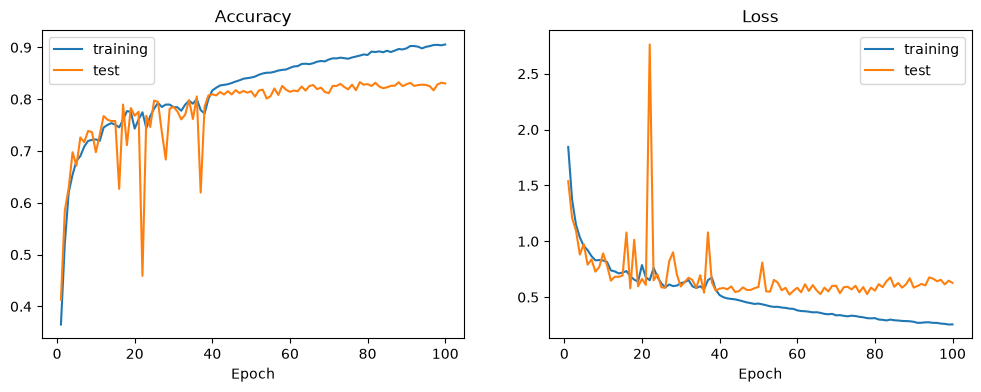

Found 7099 images belonging to 8 classes.
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
              precision    recall  f1-score   support

       anger      0.792     0.784     0.788       644
    contempt      0.867     0.255     0.394        51
     disgust      0.774     0.421     0.545        57
        fear      0.695     0.491     0.575       167
   happiness      0.914     0.916     0.915      1827
     neutral      0.822     0.876     0.848      2597
     sadness      0.699     0.658     0.677       856
    surprise      0.861     0.856     0.858       900

    accuracy                          0.832      7099
   macro avg      0.803     0.657     0.700      7099
weighted avg      0.830     0.832     0.829      7099



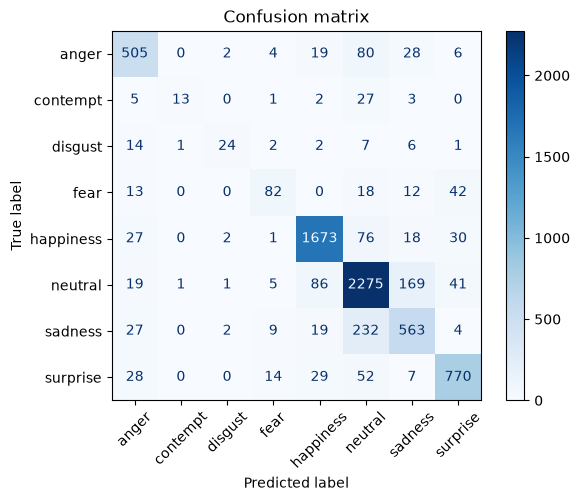

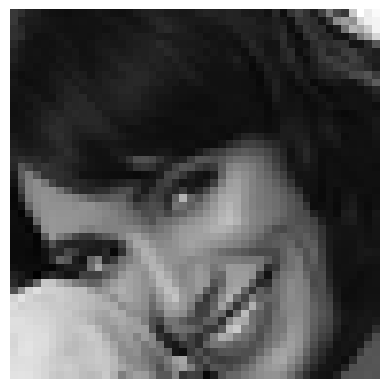

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
happiness: 1.000
neutral: 0.000
sadness: 0.000
anger: 0.000
surprise: 0.000
Prediction: happiness (actual: happiness)


In [28]:
if menu_decision == "Facial Expression Recognition":
    # FER+ (FER2013 with corrected labels) already has train and test folders.
    # The images are 48x48 grayscale, with 8 emotions.

    # 1. Load the images
    training_set = load_images(train_datagen, os.path.join(FER_DIR, "train"), fer_image_size, color_mode='grayscale')
    test_set = load_images(test_datagen, os.path.join(FER_DIR, "test"), fer_image_size, color_mode='grayscale')

    # 2. Train a new model, or load the saved one
    if ask_to_retrain():
        input_shape = (fer_image_size[0], fer_image_size[1], 1)  # 1 channel: grayscale
        cnn = build_cnn(input_shape, training_set.num_classes)
        history = train_and_save(cnn, training_set, test_set)
    else:
        cnn = load_saved_model()
        history = None  # a loaded model has no training curves

    # 3. Evaluate it
    evaluate_model(cnn, history, os.path.join(FER_DIR, "test"), fer_image_size, color_mode='grayscale')

    # 4. Predict a random test image
    predict_random_test_image(cnn, test_set, fer_image_size, color_mode='grayscale')
else:
    print(f"Skipped: the selected dataset is {menu_decision}")

### 7.2 Face Mask Detection

In [29]:
if menu_decision == "Face Mask Detection":
    # This dataset has no test folder, so make a random train/test split (only the first time).
    # The split has 3 classes (incorrect_mask, with_mask, without_mask), but only mask_classes are loaded.
    make_train_test_split(os.path.join(DATASET_DIR, "FMD_DATASET"), MASK_SPLIT_DIR, test_share)

    # 1. Load the images
    training_set = load_images(train_datagen, os.path.join(MASK_SPLIT_DIR, "train"), image_size, classes=mask_classes)
    test_set = load_images(test_datagen, os.path.join(MASK_SPLIT_DIR, "test"), image_size, classes=mask_classes)

    # 2. Train a new model, or load the saved one
    if ask_to_retrain():
        input_shape = (image_size[0], image_size[1], 3)  # 3 channels: color
        cnn = build_cnn(input_shape, training_set.num_classes)
        history = train_and_save(cnn, training_set, test_set)
    else:
        cnn = load_saved_model()
        history = None  # a loaded model has no training curves

    # 3. Evaluate it
    evaluate_model(cnn, history, os.path.join(MASK_SPLIT_DIR, "test"), image_size, classes=mask_classes)

    # 4. Predict a random test image
    predict_random_test_image(cnn, test_set, image_size)
else:
    print(f"Skipped: the selected dataset is {menu_decision}")

Skipped: the selected dataset is Facial Expression Recognition


### 7.3 Fruit and Vegetable Recognition

In [30]:
if menu_decision == "Fruit and Vegetable Recognition":
    # The dataset already has Training and Test folders, with a folder for every variety.
    # Merge the varieties of each fruit in fruit_names into one folder, without the dropped varieties (only the first time).
    make_fruit_subset(FRUITS_DIR, FRUITS_SUBSET_DIR, fruit_names, dropped_fruit_varieties)

    # 1. Load the images
    training_set = load_images(train_datagen, os.path.join(FRUITS_SUBSET_DIR, "Training"), image_size)
    test_set = load_images(test_datagen, os.path.join(FRUITS_SUBSET_DIR, "Test"), image_size)

    # 2. Train a new model, or load the saved one
    if ask_to_retrain():
        input_shape = (image_size[0], image_size[1], 3)  # 3 channels: color
        cnn = build_cnn(input_shape, training_set.num_classes)
        # There are far more apple and tomato images than eggplant ones, so balance the classes
        history = train_and_save(cnn, training_set, test_set, balance_classes=True)
    else:
        cnn = load_saved_model()
        history = None  # a loaded model has no training curves

    # 3. Evaluate it
    evaluate_model(cnn, history, os.path.join(FRUITS_SUBSET_DIR, "Test"), image_size)

    # 4. Predict a random test image
    predict_random_test_image(cnn, test_set, image_size)
else:
    print(f"Skipped: the selected dataset is {menu_decision}")

Skipped: the selected dataset is Facial Expression Recognition
